# TP3 – Question-réponse générative : RAG vs Non-RAG

**IFT-7022 – Traitement automatique de la langue naturelle (Automne 2026)**

On compare deux approches de question-réponse générative avec **le même LLM** :

- **Non-RAG** (QA fermé) : le LLM répond seulement avec ses connaissances.
- **RAG** (QA ouvert) : des passages Wikipedia récupérés avec FAISS sont ajoutés au *prompt*.

Données : `data/test_questions.json` (50 questions) et `data/train_texts.json` (passages Wikipedia).

**Plan**

1. Configuration
2. Données
3. Évaluation
4. LLM et génération
5. Choix du modèle
6. Non-RAG
7. RAG – Indexation et recherche
8. RAG – Génération
9. Comparaison RAG vs Non-RAG

## 1. Configuration

In [ ]:
#%pip install -q -U transformers accelerate sentence-transformers faiss-cpu langchain-text-splitters
%pip install -q faiss-cpu langchain-text-splitters

In [7]:
import os, re, gc, json, time, string, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import faiss
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 200)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Device : cuda | Tesla T4


In [ ]:
CONFIG = {
    # Chemins
    "data_dir": "data",
    "results_dir": "results",
    "index_dir": "data/index_faiss",
    "seed": 42,

    # LLM
    "candidate_llms": [
        "Qwen/Qwen2.5-3B-Instruct",
        "microsoft/Phi-4-mini-instruct",
        "HuggingFaceTB/SmolLM3-3B",
    ],
    "llm_name": None,            # fixé à la section 5
    "generation": {"max_new_tokens": 128, "do_sample": False, "repetition_penalty": 1.1},

    # Non-RAG
    "nonrag_variant": None,      # fixé à la section 6

    # RAG
    "embedding_model": None,     # fixé à la section 7
    "top_k": None,               # fixé à la section 8
    "rag_variant": None,         # fixé à la section 8

    # Évaluation
    "eval_embedding_model": "sentence-transformers/all-mpnet-base-v2",
}

os.makedirs(CONFIG["results_dir"], exist_ok=True)
os.makedirs(CONFIG["index_dir"], exist_ok=True)
set_seed(CONFIG["seed"]); random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"])

## 2. Données

In [9]:
def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

questions = load_json(os.path.join(CONFIG["data_dir"], "test_questions.json"))
for i, q in enumerate(questions):
    q["id"] = i

passages = load_json(os.path.join(CONFIG["data_dir"], "train_texts.json"))

print(f"{len(questions)} questions | {len(passages)} passages | "
      f"{len({p['title'] for p in passages})} pages Wikipedia")

50 questions | 747 passages | 22 pages Wikipedia


In [31]:
df_passages = pd.DataFrame(passages)
ref_words = pd.Series([len(q["answer"].split()) for q in questions])

print("Longueur des passages (mots) :\n", df_passages["word_count"].describe().round(1), "\n")
print("Longueur des réponses de référence (mots) :\n", ref_words.describe().round(1))

Longueur des passages (mots) :
 count    747.0
mean      99.1
std       34.3
min       10.0
25%       72.0
50%      112.0
75%      123.0
max      160.0
Name: word_count, dtype: float64 

Longueur des réponses de référence (mots) :
 count    50.0
mean     21.6
std      11.5
min       2.0
25%      13.0
50%      20.0
75%      29.8
max      49.0
dtype: float64


## 3. Évaluation

Pour chaque réponse générée :

| Métrique | Pourquoi |
|---|---|
| Précision, rappel, F1 (jetons) | Références sont des phrases complètes, le F1 pénalise les réponses trop courtes et trop longues ; le rappel mesure la couverture de la référence. |
| Similarité sémantique | Cosinus entre plongements (référence, prédiction). Tolère les reformulations. |
| Abstention | Le modèle dit qu'il ne sait pas. |
| Longueur, temps | Verbosité et coût. |

In [32]:
# --- F1 au niveau des jetons ---
PUNCT = set(string.punctuation)

def normalize_answer(s):
    """Minuscules, sans ponctuation, sans déterminants, espaces normalisés."""
    s = s.lower()
    s = "".join(ch for ch in s if ch not in PUNCT)
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def evaluate_f1(ground_truth, prediction):
    pred_tokens = normalize_answer(prediction).split()
    gt_tokens = normalize_answer(ground_truth).split()
    num_same = sum((Counter(pred_tokens) & Counter(gt_tokens)).values())
    if num_same == 0:
        return 0.0, 0.0, 0.0
    precision = num_same / len(pred_tokens)
    recall = num_same / len(gt_tokens)
    return precision, recall, 2 * precision * recall / (precision + recall)


# --- Autres métriques ---
ABSTENTION_PATTERNS = ["i don't know", "i do not know", "not mentioned in the context",
                       "not provided in the context", "cannot answer", "no information"]

def is_abstention(prediction):
    return any(p in prediction.lower() for p in ABSTENTION_PATTERNS)

_eval_encoder = None
def semantic_similarity(references, predictions):
    global _eval_encoder
    if _eval_encoder is None:
        _eval_encoder = SentenceTransformer(CONFIG["eval_embedding_model"], device=DEVICE)
    ref = _eval_encoder.encode(references, normalize_embeddings=True)
    pred = _eval_encoder.encode(predictions, normalize_embeddings=True)
    return (ref * pred).sum(axis=1)


# --- Évaluation d'un run complet ---
def evaluate_run(results):
    """Résultats (format commun) -> DataFrame, une ligne par question."""
    rows = []
    for r in results:
        p, rc, f1 = evaluate_f1(r["reference"], r["prediction"])
        rows.append({"id": r["id"], "precision": p, "recall": rc, "f1": f1,
                     "abstention": is_abstention(r["prediction"]),
                     "n_words": len(r["prediction"].split()), "latency_s": r["latency_s"]})
    df = pd.DataFrame(rows)
    df["sem_sim"] = semantic_similarity([r["reference"] for r in results],
                                        [r["prediction"] for r in results])
    return df

def summarize(df, name=None):
    """Moyennes d'un run (une ligne de tableau)."""
    cols = ["precision", "recall", "f1", "sem_sim", "abstention", "n_words", "latency_s"]
    return df[cols].mean().round(3).rename(name)


# --- Sauvegarde ---
def save_results(results, name):
    path = os.path.join(CONFIG["results_dir"], f"{name}.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=2)
    print("Sauvegardé :", path)

def load_results(name):
    return load_json(os.path.join(CONFIG["results_dir"], f"{name}.json"))

In [33]:
# Vérification rapide
evaluate_f1("GPT-3 has a context window size of 2,048 tokens.",
            "The context window of GPT-3 is 2,048 tokens.")

(0.8571428571428571, 0.75, 0.7999999999999999)

## 4. LLM et génération

- `apply_chat_template` : les candidats sont *instruct-tuned*, on respecte leur format de conversation.
- Décodage *greedy* (`do_sample=False`) : réponses déterministes, donc comparaison équitable entre RAG et Non-RAG.
- `enable_thinking=False` : désactive le mode raisonnement (SmolLM3) ; ignoré par les autres modèles.
- `run_qa` est la boucle commune aux deux systèmes : elle reçoit la fonction qui construit le *prompt* et, pour le RAG, la fonction de recherche.

In [34]:
def load_llm(model_name):
    if DEVICE == "cuda":
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    else:
        dtype = torch.float32
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=dtype, device_map="auto")
    model.eval()
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    print(f"{model_name} : {sum(p.numel() for p in model.parameters()) / 1e9:.2f}B paramètres")
    return model, tokenizer

def clear_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

@torch.no_grad()
def generate_answer(messages, model, tokenizer):
    prompt = tokenizer.apply_chat_template(messages, tokenize=False,
                                           add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
    output = model.generate(**inputs, **CONFIG["generation"], pad_token_id=tokenizer.pad_token_id)
    answer = tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return re.sub(r"<think>.*?</think>", "", answer, flags=re.DOTALL).strip()

def run_qa(questions, model, tokenizer, build_messages, system, variant, retrieve_fn=None, k=0):
    """Boucle commune Non-RAG / RAG -> liste de résultats au format commun.
    build_messages(question, retrieved) -> messages ; retrieve_fn(question, k) -> passages."""
    results = []
    for q in questions:
        t0 = time.time()
        retrieved = retrieve_fn(q["question"], k) if retrieve_fn else []
        prediction = generate_answer(build_messages(q["question"], retrieved), model, tokenizer)
        results.append({
            "id": q["id"], "question": q["question"], "reference": q["answer"],
            "prediction": prediction, "system": system, "variant": variant, "k": k,
            "passages": [p["chunk_id"] for p in retrieved],
            "latency_s": round(time.time() - t0, 2),
        })
    return results

### 4.1 Prompts Non-RAG

| Variante | Idée |
|---|---|
| `zero_shot` | La question seule, comme dans TP2. |
| `concise` | Consigne : expert en IA, 1-2 phrases complètes, « I don't know » si le modèle ne sait pas. Rapproche la forme des références et limite les hallucinations. |
| `few_shot` | `concise` + 2 exemples **hors des 50 questions de test** pour montrer le style attendu. |

In [35]:
SYSTEM_NONRAG = (
    "You are a helpful assistant specialized in artificial intelligence and large language models. "
    "Answer the question accurately in one or two complete sentences. "
    "If you do not know the answer, say \"I don't know\"."
)

FEW_SHOT_EXAMPLES = [
    ("What is word2vec?",
     "Word2vec is a technique that learns dense vector representations of words "
     "from large text corpora using a shallow neural network."),
    ("Who developed BERT and when was it released?",
     "BERT was developed by researchers at Google and was released in 2018."),
]

def nonrag_prompt(variant):
    """Retourne une fonction build_messages(question, retrieved) pour la variante donnée."""
    def build(question, retrieved=None):
        if variant == "zero_shot":
            return [{"role": "user", "content": question}]
        messages = [{"role": "system", "content": SYSTEM_NONRAG}]
        if variant == "few_shot":
            for q, a in FEW_SHOT_EXAMPLES:
                messages += [{"role": "user", "content": q}, {"role": "assistant", "content": a}]
        messages.append({"role": "user", "content": question})
        return messages
    return build

NONRAG_VARIANTS = ["zero_shot", "concise", "few_shot"]
nonrag_prompt("few_shot")(questions[0]["question"])

[{'role': 'system',
  'content': 'You are a helpful assistant specialized in artificial intelligence and large language models. Answer the question accurately in one or two complete sentences. If you do not know the answer, say "I don\'t know".'},
 {'role': 'user', 'content': 'What is word2vec?'},
 {'role': 'assistant',
  'content': 'Word2vec is a technique that learns dense vector representations of words from large text corpora using a shallow neural network.'},
 {'role': 'user', 'content': 'Who developed BERT and when was it released?'},
 {'role': 'assistant',
  'content': 'BERT was developed by researchers at Google and was released in 2018.'},
 {'role': 'user', 'content': 'What is the context window size of GPT-3?'}]

In [36]:
# --- Outils minimaux pour le mini-test seulement ---
def make_test_retriever(passages, model_name="sentence-transformers/all-MiniLM-L6-v2"):
    encoder = SentenceTransformer(model_name, device=DEVICE)
    emb = encoder.encode([f"{p['title']}: {p['text']}" for p in passages], normalize_embeddings=True)
    index = faiss.IndexFlatIP(emb.shape[1])
    index.add(emb.astype("float32"))
    def retrieve(question, k):
        q = encoder.encode([question], normalize_embeddings=True).astype("float32")
        scores, idx = index.search(q, k)
        return [{**passages[i], "score": float(s)} for s, i in zip(scores[0], idx[0])]
    return retrieve

def test_rag_prompt(question, retrieved):
    context = "\n\n".join(f"[{i+1}] {p['text']}" for i, p in enumerate(retrieved))
    return [{"role": "system", "content": "Answer using only the context. One or two sentences. "
                                          "If the answer is not in the context, say \"I don't know\"."},
            {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"}]

## 5. Choix du modèle

On a regardé une douzaine de modèles sur HuggingFace et on a gardé ceux qui cochaient tout :

- **Décodeur seulement**, comme demandé (pas de BERT, T5, BART).
- **Moins de 4B**, vraiment : on a laissé tomber ceux qui sont à la limite.
- **Version instruct**, pour qu'il suive bien le prompt.

| Modèle | Taille | Pourquoi |
|---|---|---|
| ✅ Qwen2.5-3B-Instruct | 3,1B | Stable, coche tout |
| ✅ Phi-4-mini-instruct | 3,8B | Le plus fort sous 4B |
| ✅ SmolLM3-3B | 3,1B | Complètement ouvert |
| ❌ Llama-3.2-3B-Instruct | 3,2B | Licence à demander, très proche de Qwen |
| ❌ Qwen3-4B, Gemma 3 4B | ~4-4,3B | À la limite ou au-dessus de 4B |
| ❌ Qwen3.5-2B | ~2B | Multimodal, demande un `transformers` très récent |
| ❌ Phi-3.5-mini, SmolLM2 | 1,7-3,8B | Remplacés par des versions plus récentes |
| ❌ Modèles de 1-1,7B | 1-1,7B | Trop petits |
| ❌ GPT-2, Pythia-410m | < 1B | Interdits par l'énoncé |

Le mini-test plus bas sert à choisir entre les trois.

**Mini-test** : 10 questions (faits stables et faits récents 2025-2026), chaque candidat en Non-RAG (`concise`) et en RAG avec une recherche minimale (k = 3). On garde le modèle qui obtient le meilleur score moyen, puis il ne change plus.

La recherche et le *prompt* RAG de cette section servent **seulement** au mini-test.

In [37]:
RUN_BAKEOFF = True
BAKEOFF_IDS = [0, 1, 6, 13, 18, 24, 33, 38, 43, 49]
bakeoff_questions = [q for q in questions if q["id"] in BAKEOFF_IDS]

if RUN_BAKEOFF:
    test_retrieve = make_test_retriever(passages)
    bakeoff_answers, rows = [], []
    for name in CONFIG["candidate_llms"]:
        model, tokenizer = load_llm(name)
        runs = {
            "non-rag": run_qa(bakeoff_questions, model, tokenizer, nonrag_prompt("concise"), "non-rag", "concise"),
            "rag": run_qa(bakeoff_questions, model, tokenizer, test_rag_prompt, "rag", "test",
                          retrieve_fn=test_retrieve, k=3),
        }
        for system, res in runs.items():
            for r in res:
                r["model"] = name
            bakeoff_answers += res
            rows.append({"model": name, "system": system, **summarize(evaluate_run(res)).to_dict()})
        del model, tokenizer
        clear_gpu()
    df_bakeoff = pd.DataFrame(rows)
    df_bakeoff.to_csv(os.path.join(CONFIG["results_dir"], "bakeoff.csv"), index=False)
    save_results(bakeoff_answers, "bakeoff_answers")
else:
    df_bakeoff = pd.read_csv(os.path.join(CONFIG["results_dir"], "bakeoff.csv"))
    bakeoff_answers = load_results("bakeoff_answers")

df_bakeoff.pivot(index="model", columns="system", values=["f1", "recall", "sem_sim", "n_words", "latency_s"])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (56 outputs left out)

HuggingFaceTB/SmolLM3-3B : 3.08B paramètres


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Sauvegardé : results/bakeoff_answers.json


f1         recall        sem_sim         \
system                        non-rag    rag non-rag    rag non-rag    rag   
model                                                                        
HuggingFaceTB/SmolLM3-3B        0.287  0.429   0.448  0.586   0.712  0.840   
Qwen/Qwen2.5-3B-Instruct        0.225  0.468   0.297  0.451   0.761  0.812   
microsoft/Phi-4-mini-instruct   0.197  0.277   0.326  0.352   0.729  0.767   

                              n_words       latency_s         
system                        non-rag   rag   non-rag    rag  
model                                                         
HuggingFaceTB/SmolLM3-3B         47.2  47.7     3.581  4.598  
Qwen/Qwen2.5-3B-Instruct         31.1  26.0     2.670  3.166  
microsoft/Phi-4-mini-instruct    49.2  52.8     3.637  5.059

In [38]:
# Réponses côte à côte (analyse qualitative du choix)
(pd.DataFrame(bakeoff_answers)[["id", "system", "model", "prediction"]]
   .sort_values(["id", "system", "model"]))

,id,system,model,prediction
40,0,non-rag,HuggingFaceTB/SmolLM3-3B,The context window size of GPT-3 is approximately 2048 tokens. This means it can process and generate text based on up to 2048 words (or tokens) preceding its input.
0,0,non-rag,Qwen/Qwen2.5-3B-Instruct,"The context window size for GPT-3 can vary depending on the specific model version used, but it typically ranges from 1024 to 8192 tokens."
20,0,non-rag,microsoft/Phi-4-mini-instruct,"The original version of GPT-3 has an input (context) limit of 2048 tokens (~800 words). However, later versions like ChatGPT have been fine-tuned to handle longer contexts by splitting them into c..."
50,0,rag,HuggingFaceTB/SmolLM3-3B,"The context window size of GPT-3 is 2,048 tokens."
10,0,rag,Qwen/Qwen2.5-3B-Instruct,"The context window size of GPT-3 is 2,048 tokens."
30,0,rag,microsoft/Phi-4-mini-instruct,"The context window size of GPT-3 is 2,048 tokens."
41,1,non-rag,HuggingFaceTB/SmolLM3-3B,"A transformer architecture is a type of neural network model that uses self-attention mechanisms to process sequential data, such as text, speech, or time series. It was introduced by Google's AI ..."
1,1,non-rag,Qwen/Qwen2.5-3B-Instruct,A transformer architecture is a type of neural network designed to process sequential data without relying on the traditional sequence-to-sequence approach using recurrent neural networks (RNNs) l...
21,1,non-rag,microsoft/Phi-4-mini-instruct,A Transformer architecture is an advanced deep learning model primarily used for natural language processing tasks that relies on self-attention mechanisms to process input data sequentially witho...
51,1,rag,HuggingFaceTB/SmolLM3-3B,"A transformer architecture is a type of deep learning framework used for natural language processing tasks, consisting of several key components including tokenizers, embedding layers, transformer..."


In [39]:
# Classement : moyenne du F1 et de la similarité sémantique (Non-RAG et RAG confondus)
ranking = (df_bakeoff.groupby("model")[["f1", "sem_sim", "n_words", "latency_s"]].mean()
           .assign(score=lambda d: (d["f1"] + d["sem_sim"]) / 2)
           .sort_values("score", ascending=False).round(3))
ranking

,f1,sem_sim,n_words,latency_s,score
model,,,,,
HuggingFaceTB/SmolLM3-3B,0.358,0.776,47.45,4.090,0.567
Qwen/Qwen2.5-3B-Instruct,0.347,0.786,28.55,2.918,0.566
microsoft/Phi-4-mini-instruct,0.237,0.748,51.00,4.348,0.492


**Décision:** Qwen2.5-3B-Instruct

SmolLM3 et Qwen sont à égalité au score (0,567 vs 0,566), une différence qui ne veut rien dire sur 10 questions. On a donc regardé le reste, et Qwen est meilleur partout :

- meilleure similarité sémantique (0,786 vs 0,776) ;
- réponses plus courtes (28 mots vs 47), plus proches des références ;
- plus rapide (2,7 s vs 4,2 s par réponse).

Phi-4-mini est clairement derrière (F1 de 0,237, réponses trop longues).

On garde donc Qwen2.5-3B-Instruct pour tout le reste du TP, en Non-RAG et en RAG.

In [40]:
CONFIG["llm_name"] = "Qwen/Qwen2.5-3B-Instruct"

model = tokenizer = None
clear_gpu()
model, tokenizer = load_llm(CONFIG["llm_name"])

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Qwen/Qwen2.5-3B-Instruct : 3.09B paramètres


## 6. Non-RAG

Les 50 questions avec chacune des 3 variantes de *prompt* ; la meilleure devient le système Non-RAG de la comparaison finale.

In [41]:
nonrag_runs, nonrag_evals = {}, {}
for v in NONRAG_VARIANTS:
    nonrag_runs[v] = run_qa(questions, model, tokenizer, nonrag_prompt(v), "non-rag", v)
    nonrag_evals[v] = evaluate_run(nonrag_runs[v])
    save_results(nonrag_runs[v], f"nonrag_{v}")

df_nonrag = pd.DataFrame([summarize(nonrag_evals[v], v) for v in NONRAG_VARIANTS])
df_nonrag

Sauvegardé : results/nonrag_zero_shot.json
Sauvegardé : results/nonrag_concise.json
Sauvegardé : results/nonrag_few_shot.json


,precision,recall,f1,sem_sim,abstention,n_words,latency_s
zero_shot,0.094,0.411,0.148,0.585,0.00,96.70,7.341
concise,0.209,0.288,0.231,0.617,0.36,27.04,2.318
few_shot,0.210,0.331,0.243,0.629,0.06,33.04,2.959


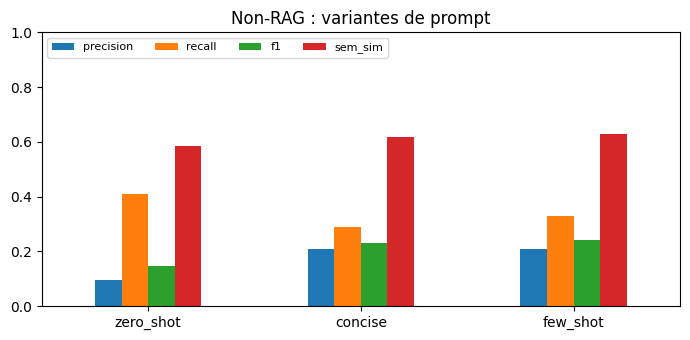

In [42]:
ax = df_nonrag[["precision", "recall", "f1", "sem_sim"]].plot.bar(rot=0, figsize=(7, 3.5), ylim=(0, 1))
ax.set_title("Non-RAG : variantes de prompt")
ax.legend(ncol=4, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

In [43]:
# Exemples : référence et réponses des 3 variantes
pd.DataFrame({
    "question": [q["question"] for q in questions],
    "reference": [q["answer"] for q in questions],
    **{v: [r["prediction"] for r in nonrag_runs[v]] for v in NONRAG_VARIANTS},
}).head(10)

,question,reference,zero_shot,concise,few_shot
0,What is the context window size of GPT-3?,"GPT-3 has a context window size of 2,048 tokens.",The context window size for GPT-3 can vary depending on the specific model and version you're referring to. GPT-3 comes in different versions with varying capabilities:\n\n1. **GPT-3**: This was t...,"The context window size for GPT-3 can vary depending on the specific model version used, but it typically ranges from 1024 to 8192 tokens.","GPT-3 does not have a specific context window size mentioned in its original specification; however, like earlier versions of Generative Pre-trained Transformer (GPT), it typically processes input..."
1,Explain what is a transformer architecture.,"The transformer architecture is a neural network based on a deep learning model that was introduced in 2017, used in natural language processing (NLP) systems.",A transformer architecture is a type of deep learning model that has revolutionized the field of natural language processing (NLP) and beyond. It was introduced as an alternative to recurrent neur...,A transformer architecture is a type of neural network designed to process sequential data without relying on the traditional sequence-to-sequence approach using recurrent neural networks (RNNs) l...,"A transformer architecture is a type of deep learning model designed for natural language processing tasks, primarily based on self-attention mechanisms rather than traditional recurrent neural ne..."
2,Define what is a generative pre-trained transformer (GPT).,"A generative pre-trained transformer is a type of generative large language model that is pre-trained with an enormous and diverse text corpus in datasets, followed by discriminative fine-tuning t...",A Generative Pre-trained Transformer (GPT) is a type of deep learning model that falls under the category of autoregressive language models. These models are designed to predict the next word in a...,A generative pre-trained transformer (GPT) is a type of deep learning model that uses transformers to generate text by predicting the next word in a sequence based on the context provided by previ...,A generative pre-trained transformer (GPT) is a type of deep learning model that uses transformers to generate human-like text by predicting the next word in a sequence based on the context provid...
3,Which sources comprise the weighted pre-training dataset for GPT-3?,"The sources are Common Crawl (60%), WebText2 (22%), Books1 (8%), Books2 (8%), and Wikipedia (3%).",I don't have access to specific details about the exact composition of the pre-training datasets used in the development of GPT-3 or any other models at Alibaba Cloud. The precise breakdown of the...,"The exact composition of the weighted pre-training dataset used for training GPT-3 is proprietary information from Anthropic, so specific details are not publicly disclosed.","I don't have specific information on the exact sources used for the weighted pre-training dataset of GPT-3. For accurate details, I would need to refer to official announcements or documentation f..."
4,List the three main classes of language modelling tasks discussed in the context of transformers?,"The three main classes are masked, autoregressive, and prefixLM tasks.","In the context of transformers and natural language processing (NLP), there are several key types of language modeling tasks that have been extensively studied. The three main classes of these tas...","The three main classes of language modelling tasks discussed in the context of transformers are autoregressive, causal, and mutual information maximization.","The three main classes of language modelling tasks discussed in the context of transformers are autoregressive, causal, and mutual information."
5,What is knowledge distillation in the context of transformer models?,"Knowledge distillation is a method for training a smaller student model to reproduce the output behavior of a larger teacher model, which can 

In [ ]:
CONFIG["nonrag_variant"] = df_nonrag["f1"].idxmax()
nonrag_final = nonrag_runs[CONFIG["nonrag_variant"]]
save_results(nonrag_final, "nonrag_answers")
print("Variante Non-RAG retenue :", CONFIG["nonrag_variant"])

Sauvegardé : results/nonrag_answers.json
Variante Non-RAG retenue : few_shot


**Variante retenue : few_shot**

- **zero_shot** : réponses très longues (97 mots en moyenne, souvent en listes), donc un bon rappel (0,41) mais une précision très faible (0,09). Le modèle « couvre » la référence en disant beaucoup de choses. C'est aussi la plus lente (7,2 s).
- **concise** : la consigne raccourcit bien les réponses (27 mots), mais le modèle répond « I don't know » à 36 % des questions, ce qui fait baisser le rappel.
- **few_shot** : le meilleur F1 (0,243) et la meilleure similarité sémantique (0,629), avec des réponses courtes (33 mots). Les deux exemples montrent le style attendu et le modèle s'abstient beaucoup moins (6 %).

En plus, les exemples ne montrent jamais de « I don't know », donc few_shot pousse le modèle à toujours répondre, même quand il ne sait pas. Sur la question 0 par exemple, aucune variante ne donne les 2 048 jetons de GPT-3, few_shot se trompe avec assurance là où concise reste vague. On garde few_shot comme système Non-RAG, mais cette tendance à inventer est justement ce que le RAG devrait corriger dans les taches suivantes.

## 7. RAG – Indexation et recherche

Pipeline : les passages Wikipedia sont indexés avec FAISS (**retriever**), puis les k passages
les plus proches de la question sont donnés au même LLM (**reader / generator**).

- 7.1 Indexation : découpage, encodeurs, index FAISS
- 7.2 Choix de l'encodeur : MiniLM vs E5
- 7.3 Choix de k

### 7.1 Indexation

In [10]:
# Passages Wikipedia chargés à la section 2
documents = passages

# Combinaison du titre, de la section et du texte
textes_passages = [
    f"{doc['title']}\n{doc['section']}\n{doc['text']}"
    for doc in documents
]

print("\nExemple de passage :\n")
print(textes_passages[0])


Exemple de passage :

GPT-3
Introduction
Generative Pre-trained Transformer 3 (GPT-3) was a large language model released by OpenAI in 2020 as part of the company's GPT series of models. Like its predecessor, GPT-2, it is a decoder-only transformer model of deep neural network, which supersedes recurrence and convolution-based architectures with a technique known as "attention". This attention mechanism allows the model to focus selectively on segments of input text it predicts to be most relevant. GPT-3 has 175 billion parameters, each with 16-bit precision, requiring 350GB of storage since each parameter occupies 2 bytes. It has a context window size of 2,048 tokens, and has demonstrated strong "zero-shot" and "few-shot" learning abilities on many tasks.


#### 7.1.1 Modèles d'embeddings

- **MiniLM** (`paraphrase-multilingual-MiniLM-L12-v2`) : petit modèle, limite fixée à 256 tokens.
- **E5** (`multilingual-e5-large-instruct`) : modèle plus grand, entraîné pour la recherche, limite de 512 tokens.
  Les requêtes reçoivent une instruction, les passages aucun préfixe.

In [11]:
# Charger les modèles d'embeddings une seule fois : MiniLM, E5

# Identifiants des modèles
MODELE_MINILM = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODELE_E5 = "intfloat/multilingual-e5-large-instruct"

# Charger MiniLM
modele_minilm = SentenceTransformer(MODELE_MINILM)
modele_minilm.max_seq_length = 256

# Charger E5
modele_e5 = SentenceTransformer(MODELE_E5)

# Regrouper les modèles
modeles = {
    "minilm": modele_minilm,
    "e5": modele_e5,
}

# Afficher les limites de chaque modèle
for nom, modele in modeles.items():
    print(f"{nom} : limite configurée de {modele.max_seq_length} tokens")


# Format des requêtes
# E5-instruct attend "Instruct: <tâche>\nQuery: <question>" pour les requêtes.
# Les passages sont encodés sans préfixe. MiniLM n'utilise aucun préfixe.
INSTRUCTION_E5 = "Given a question, retrieve Wikipedia passages that answer the question"

def formater_requete(nom, question):
    if nom == "e5":
        return f"Instruct: {INSTRUCTION_E5}\nQuery: {question}"
    return question

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (19 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

minilm : limite configurée de 256 tokens
e5 : limite configurée de 512 tokens


#### 7.1.2 Longueur des passages et découpage

On vérifie combien de passages dépassent la limite de chaque modèle. Seuls ces passages sont découpés
(taille = limite du modèle, chevauchement de 40 tokens), en répétant le titre et la section dans chaque morceau.

In [12]:
# Vérifier les longueurs des passages avant découpage

resultats_longueurs = []

for nom, modele in modeles.items():

    tokenizer = modele.tokenizer
    limite = modele.max_seq_length

    longueurs = [
        len(tokenizer.encode(
            texte,
            add_special_tokens=True,
            truncation=False,
            verbose=False
        ))
        for texte in textes_passages
    ]

    resultats_longueurs.append({
        "Modèle": nom,
        "Nombre de passages": len(longueurs),
        "Limite tokens": limite,
        "Maximum observé": max(longueurs) if longueurs else 0,
        "Médiane": int(pd.Series(longueurs).median()) if longueurs else 0,
        "Passages dépassant la limite": sum(
            longueur > limite for longueur in longueurs
        )
    })

df_longueurs = pd.DataFrame(resultats_longueurs)

display(df_longueurs)

,Modèle,Nombre de passages,Limite tokens,Maximum observé,Médiane,Passages dépassant la limite
0,minilm,747,256,286,179,6
1,e5,747,512,286,179,0


In [13]:
def decouper_passages(documents, modele, taille=200, chevauchement=40):

    tokenizer = modele.tokenizer
    limite = modele.max_seq_length
    morceaux = []

    assert taille > 0
    assert 0 <= chevauchement < taille

    for doc in documents:

        # Informations conservées dans chaque morceau
        titre = doc["title"]
        section = doc["section"]
        texte = doc["text"]

        entete = f"{titre}\n{section}\n"

        # Tokens de l'en-tête
        nb_entete = len(tokenizer.encode(
            entete, add_special_tokens=False
        ))

        # Place disponible pour le texte
        nb_speciaux = tokenizer.num_special_tokens_to_add(pair=False)
        espace = min(taille, limite) - nb_entete - nb_speciaux

        if espace <= chevauchement:
            raise ValueError("En-tête trop long ou chevauchement trop grand")

        # Découpage du texte seulement
        tokens = tokenizer.encode(
            texte,
            add_special_tokens=False,
            truncation=False
        )

        pas = espace - chevauchement

        for numero, debut in enumerate(range(0, len(tokens), pas), start=1):

            fin = min(debut + espace, len(tokens))

            morceau_texte = tokenizer.decode(
                tokens[debut:fin],
                skip_special_tokens=True
            )

            morceau = entete + morceau_texte

            morceaux.append({
                "chunk_id": doc["chunk_id"],
                "numero_morceau": numero,
                "texte_embedding": morceau
            })

            if fin == len(tokens):
                break

    return pd.DataFrame(morceaux)

# Découpage MiniLM
morceaux_minilm = decouper_passages(
    documents,
    modele_minilm,
    taille=modele_minilm.max_seq_length,
    chevauchement=40
)

morceaux_e5 = decouper_passages(
    documents,
    modele_e5,
    taille=modele_e5.max_seq_length,
    chevauchement=40
)

print("MiniLM :", len(morceaux_minilm), "morceaux")
print("E5 :", len(morceaux_e5), "morceaux")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (264 > 256). Running this sequence through the model will result in indexing errors


MiniLM : 753 morceaux
E5 : 747 morceaux


#### 7.1.3 Construction des index FAISS

Index exact `IndexFlatIP` sur des vecteurs normalisés : le produit scalaire correspond à la similarité cosinus.
Les `chunk_id` sont sauvegardés dans le même ordre que les vecteurs.

In [22]:
# Construction et sauvegarde des index FAISS (un par modèle)

morceaux_par_modele = {
    "minilm": morceaux_minilm,
    "e5": morceaux_e5,
}

for nom, modele in modeles.items():

    morceaux = morceaux_par_modele[nom]

    # Embeddings des passages (aucun préfixe pour les deux modèles)
    vecteurs = modele.encode(
        morceaux["texte_embedding"].tolist(),
        batch_size=32,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True
    ).astype("float32")

    # Index exact par produit scalaire (similarité cosinus sur vecteurs normalisés)
    index = faiss.IndexFlatIP(vecteurs.shape[1])
    index.add(vecteurs)

        # Sauvegarder l'index et les chunk_id dans le même ordre que les vecteurs
    faiss.write_index(index, os.path.join(CONFIG["index_dir"], f"{nom}.faiss"))
    with open(os.path.join(CONFIG["index_dir"], f"{nom}.json"), "w", encoding="utf-8") as f:
        json.dump(morceaux["chunk_id"].tolist(), f, ensure_ascii=False)

    print(f"{nom} : {index.ntotal} vecteurs de dimension {vecteurs.shape[1]}")

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

minilm : 753 vecteurs de dimension 384


Batches:   0%|          | 0/24 [00:00<?, ?it/s]

e5 : 747 vecteurs de dimension 1024


### 7.2 Choix de l'encodeur : MiniLM vs E5

Protocole :

- 5 questions tirées au hasard (`random.seed(42)`), les mêmes pour les deux modèles ;
- pour chaque question, les 10 premiers passages **distincts** retournés par chaque index ;
- annotation manuelle de la pertinence (1/0) dans `results/evaluation_<modèle>.xlsx` ;
- calcul de Precision@k, RR et AP par question, puis MRR@10 et MAP@10 par modèle.

In [24]:
# Choisir les mêmes 5 questions pour les deux modèles
random.seed(CONFIG["seed"])
questions_selectionnees = random.sample(
    list(enumerate(questions)), 5
)

# Retrouver les textes originaux grâce au chunk_id
documents_par_id = {
    doc["chunk_id"]: doc for doc in documents
}

for nom, modele in modeles.items():

    # Charger FAISS et les identifiants
    index = faiss.read_index(os.path.join(CONFIG["index_dir"], f"{nom}.faiss"))

    with open(os.path.join(CONFIG["index_dir"], f"{nom}.json"), encoding="utf-8") as f:
        ids = json.load(f)

    assert len(ids) == index.ntotal

    # Retrouver les morceaux dans leur ordre d'indexation
    morceaux = morceaux_e5 if nom.lower() == "e5" else morceaux_minilm
    assert len(morceaux) == index.ntotal
    assert ids == morceaux["chunk_id"].tolist()

    resultats = []

    for indice_question, question in questions_selectionnees:

        texte_question = question["question"]

        # Format de requête propre à chaque modèle
        # (E5-instruct : instruction + question ; MiniLM : question brute)
        requete = formater_requete(nom, texte_question)

        # Embedding de la question
        vecteur = modele.encode(
            [requete],
            normalize_embeddings=True,
            convert_to_numpy=True
        ).astype("float32")

        # Rechercher davantage de morceaux pour compenser les doublons
        scores, positions = index.search(
            vecteur,
            min(20, index.ntotal)
        )

        # Éviter de récupérer deux fois le même passage original
        chunk_ids_vus = set()
        rang = 0

        for score, position in zip(scores[0], positions[0]):

            if position < 0:
                continue

            chunk_id = ids[int(position)]

            # Ignorer si ce chunk_id a déjà été retrouvé
            if chunk_id in chunk_ids_vus:
                continue

            chunk_ids_vus.add(chunk_id)

            doc = documents_par_id[chunk_id]
            morceau = morceaux.iloc[int(position)]

            # Rang parmi les passages distincts
            rang += 1

            resultats.append({
                "Question ID": indice_question + 1,
                "Question": texte_question,
                "Réponse attendue": question["answer"],
                "Rang": rang,
                "Position FAISS": int(position),
                "Chunk ID": chunk_id,
                "Score FAISS": float(score),
                "Titre": doc["title"],
                "Section": doc["section"],
                "Texte retrouvé": doc["text"],
                "Pertinent (1/0)": None
            })

            # Arrêter après 10 passages différents
            if rang == 10:
                break

    # Exporter vers Excel
    df_resultats = pd.DataFrame(resultats)

    fichier = os.path.join(CONFIG["results_dir"], f"evaluation_{nom}.xlsx")

    # Ne jamais écraser un fichier déjà annoté à la main
    if os.path.exists(fichier):
        print(f"{nom} : {fichier} existe déjà, non écrasé (annotations conservées)")
    else:
        df_resultats.to_excel(fichier, index=False)
        print(f"{nom} : {len(df_resultats)} résultats → {fichier}")

minilm : 50 résultats → results/evaluation_minilm.xlsx
e5 : 50 résultats → results/evaluation_e5.xlsx


In [26]:
k_valeurs = [2, 3, 4, 5, 10]
resultats = []

for nom in ["minilm", "e5"]:

    df = pd.read_excel(os.path.join(CONFIG["results_dir"], f"evaluation_{nom}.xlsx"))

    for question_id, groupe in df.groupby("Question ID"):

        # Rangs des passages annotés pertinents (lus dans la colonne Rang)
        rangs_pertinents = np.sort(groupe.loc[groupe["Pertinent (1/0)"] == 1, "Rang"].to_numpy())

        # Precision@k : nombre de pertinents de rang <= k, divisé par k
        precisions = {f"Precision@{k}": (rangs_pertinents <= k).sum() / k for k in k_valeurs}

        # RR : inverse du rang du premier pertinent
        rr = 1 / rangs_pertinents[0] if len(rangs_pertinents) > 0 else 0.0

        # AP : moyenne des précisions aux rangs des pertinents
        ap = np.mean([i / r for i, r in enumerate(rangs_pertinents, start=1)]) if len(rangs_pertinents) > 0 else 0.0

        resultats.append({"Modèle": nom, "Question ID": question_id, **precisions, "AP@10": ap, "RR@10": rr})

# Métriques par question
df_questions = pd.DataFrame(resultats)
display(df_questions.round(4))

# Moyennes par modèle (MAP et MRR)
df_comparaison = (
    df_questions.drop(columns="Question ID")
    .groupby("Modèle").mean()
    .rename(columns={"AP@10": "MAP@10", "RR@10": "MRR@10"})
    .round(4)
)
display(df_comparaison)

# Export
with pd.ExcelWriter(os.path.join(CONFIG["results_dir"], "comparaison_metriques.xlsx")) as writer:
    df_questions.round(4).to_excel(writer, sheet_name="Par question", index=False)
    df_comparaison.to_excel(writer, sheet_name="Comparaison modèles")

,Modèle,Question ID,Precision@2,Precision@3,Precision@4,Precision@5,Precision@10,AP@10,RR@10
0,minilm,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,minilm,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,minilm,18,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,minilm,41,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,minilm,48,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,e5,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,e5,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,e5,18,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,e5,41,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,e5,48,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,Precision@2,Precision@3,Precision@4,Precision@5,Precision@10,MAP@10,MRR@10
Modèle,,,,,,,
e5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
minilm,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Conclusion :** E5 est nettement meilleur que MiniLM sur toutes les métriques
(MAP@10 : 0,85 contre 0,41 ; MRR@10 : 1,00 contre 0,59 ; Precision@5 : 0,52 contre 0,24).
E5 a toujours un passage pertinent comme première réponse (MRR@10 = 1).

**E5 est retenu pour le RAG.**

### 7.3 Choix de k

Pour E5 seulement, comment évolue les métriques selon k passages.

In [28]:
# Choix de k pour E5 : précision et pertinents récupérés selon le nombre de passages
df = pd.read_excel(os.path.join(CONFIG["results_dir"], "evaluation_e5.xlsx"))
rangs = df.loc[df["Pertinent (1/0)"] == 1, ["Question ID", "Rang"]]
total_pertinents = len(rangs)
nb_questions = df["Question ID"].nunique()

lignes = []

for k in range(1, 11):
    dans_top_k = rangs[rangs["Rang"] <= k]
    lignes.append({
        "k": k,
        "Precision@k": len(dans_top_k) / (k * nb_questions),
        "Pertinents récupérés": f"{len(dans_top_k)} / {total_pertinents}",
        "% pertinents récupérés": len(dans_top_k) / total_pertinents,
        "Questions avec ≥ 1 pertinent": dans_top_k["Question ID"].nunique(),
    })

df_choix_k = pd.DataFrame(lignes).round(2)
display(df_choix_k)

,k,Precision@k,Pertinents récupérés,% pertinents récupérés,Questions avec ≥ 1 pertinent
0,1,1.00,5 / 16,0.31,5
1,2,0.80,8 / 16,0.50,5
2,3,0.53,8 / 16,0.50,5
3,4,0.50,10 / 16,0.62,5
4,5,0.52,13 / 16,0.81,5
5,6,0.47,14 / 16,0.88,5
6,7,0.46,16 / 16,1.00,5
7,8,0.40,16 / 16,1.00,5
8,9,0.36,16 / 16,1.00,5
9,10,0.32,16 / 16,1.00,5


**Conclusion :** on retient **k = 5**.

Avec 5 passages, on récupère 81 % des passages pertinents
(13 / 16) avec une précision de 0,52, et chaque question a au moins un passage pertinent.

Au-delà de k = 7, il n'y a plus de gain : tous les passages pertinents trouvés sont déjà dans le top 7.

## 8. RAG – Génération

### 8.1 Recherche des passages

La fonction `rechercher(question)` retourne les `K_RAG` passages distincts les plus proches
de la question avec l'index E5.

In [29]:
# Configuration retenue pour le RAG
NOM_MODELE_RAG = "e5"
K_RAG = 5

modele_rag = modeles[NOM_MODELE_RAG]
index_rag = faiss.read_index(os.path.join(CONFIG["index_dir"], f"{NOM_MODELE_RAG}.faiss"))

with open(os.path.join(CONFIG["index_dir"], f"{NOM_MODELE_RAG}.json"), encoding="utf-8") as f:
    ids_rag = json.load(f)

documents_par_id = {doc["chunk_id"]: doc for doc in documents}

def rechercher(question, k=K_RAG):
    """Retourne les k passages distincts les plus proches de la question."""

    vecteur = modele_rag.encode(
        [formater_requete(NOM_MODELE_RAG, question)],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    # Chercher un peu plus large pour pouvoir retirer les doublons
    scores, positions = index_rag.search(vecteur, min(3 * k, index_rag.ntotal))

    passages_trouves = []
    chunk_ids_vus = set()

    for score, position in zip(scores[0], positions[0]):

        if position < 0:
            continue

        chunk_id = ids_rag[int(position)]
        if chunk_id in chunk_ids_vus:
            continue
        chunk_ids_vus.add(chunk_id)

        doc = documents_par_id[chunk_id]
        passages_trouves.append({
            "chunk_id": chunk_id,
            "titre": doc["title"],
            "section": doc["section"],
            "texte": doc["text"],
            "score": float(score),
        })

        if len(passages_trouves) == k:
            break

    return passages_trouves


# Exemple
for rang, p in enumerate(rechercher(questions[0]["question"]), start=1):
    print(f"{rang}. {p['chunk_id']} | {p['score']:.3f} | {p['titre']} / {p['section']}")

1. gpt_3_001 | 0.868 | GPT-3 / Introduction
2. gpt_4_003 | 0.861 | GPT-4 / Capabilities
3. gpt_3_016 | 0.856 | GPT-3 / GPT-3.5 > GPT-3.5 with browsing
4. gpt_3_018 | 0.855 | GPT-3 / Reception > Applications
5. gpt_3_009 | 0.853 | GPT-3 / Training and capabilities


In [30]:
# Configuration retenue pour le RAG (sections 7.2 et 7.3)
CONFIG["embedding_model"] = MODELE_E5
CONFIG["top_k"] = K_RAG
print("Encodeur :", CONFIG["embedding_model"], "| k =", CONFIG["top_k"])

Encodeur : intfloat/multilingual-e5-large-instruct | k = 5


### 8.2 Prompt et réponses

_Section à compléter._

In [ ]:
# TODO : template(s) de prompt RAG : build_messages(question, retrieved) -> messages
#        (retrieved = sortie de rechercher : dicts {chunk_id, titre, section, texte, score})
# TODO : CONFIG["rag_variant"] (k est fixé à la section 7.3 : CONFIG["top_k"])
# TODO : run final avec run_qa(..., retrieve_fn=rechercher, k=CONFIG["top_k"])
#        puis save_results(rag_final, "rag_answers")

## 9. Comparaison RAG vs Non-RAG

_Section à compléter._

In [ ]:
# TODO : tableau global (summarize sur nonrag_final et rag_final) -> results/comparison.csv
# TODO : comparaison par question et par type de question, graphiques